# Leak-free data enrichment for gradient-boosted trees

**Task.** For every delivery date and zone (`ZONE_0`..`ZONE_3`), reconstruct 96 quarter-hour prices from the 24 hourly prices of that day, such that the mean of the four quarters of every hour equals the supplied hourly price within 1e-4 EUR/MWh. Score: MAE per day and zone, averaged over days, then equally over zones; the reference is the flat baseline that repeats each hourly price four times.

**What this notebook produces.** A feature table for XGBoost / CatBoost / LightGBM with one row per `(delivery_date, market_id, hour_index, quarter_index)` and the intra-hour residual as target:

- `data/enriched/train_enriched.parquet` (139,392 rows)
- `data/enriched/feature_metadata.json` (`target_col`, `categorical_cols`, `feature_cols`, feature groups, dtypes, splits, parameters, check results)
- `artifacts/figures/dataprocess_example_day.png`
- `artifacts/splits/monthly_protocol_enriched/`: the evaluation folds MOSAIC, HORIZON and HARVEST with fold-aware enriched features (Stage 5). The GBDT notebooks train and score on these files.
- `artifacts/figures/validation_protocols.png`

All logic lives in [`src/gradient/features.py`](../src/gradient/features.py) so the frozen inference pipeline imports exactly the same code. This notebook documents each stage, runs it, and verifies the leakage rules.

## Input availability rules (from `data/README.txt` and the challenge PDF)

| Source | Available for evaluated date D | Used here for |
|---|---|---|
| `test_hourly.csv`: 24 hourly prices of D, all zones | yes, all 24 hours at once | hourly-curve geometry (leads **and** lags within D), daily context, cross-zone context |
| `history_15min.csv`: quarter-hour prices | only dates strictly before D | lags, rolling shape statistics, slope response, D-1 boundary |
| quarter-hour prices of D | **never** | only to attach the training target |
| hourly curve of D+1 | **never** | nothing |
| external data / calendars / pretrained models | **prohibited** | nothing |

The two DST change dates (2025-10-26, 2026-03-29) are excluded from the package. They stay as **gaps**: history is addressed by calendar day (`D - k`), never by "previous available row".

## Stages

1. Schema, target and baseline
2. Hourly-curve features of day D
3. Historical quarter-hour features (dates < D)
4. `build_features`, dtypes, leakage checks, diagnostics, save
5. Evaluation splits: MOSAIC, HORIZON and HARVEST folds with fold-aware features

## Reproduce

```sh
uv sync
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/dataprocess.ipynb
```

In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.gradient import features as F

DATA_PATH = ROOT / 'data' / 'train_prices_15min.csv'
OUT_DIR = ROOT / 'data' / 'enriched'
FIG_DIR = ROOT / 'artifacts' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
VERSIONS = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'pyarrow': pyarrow.__version__,
    'matplotlib': matplotlib.__version__,
}
VERSIONS

{'python': '3.14.6',
 'numpy': '2.5.4',
 'pandas': '3.0.6',
 'pyarrow': '26.0.0',
 'matplotlib': '3.11.2'}

## Stage 1: schema, target and baseline

`F.load_15min` parses `delivery_date` as a naive CET/CEST market date and validates the file: unique keys, `hour_index` 1..24, `quarter_index` 1..4, finite prices, only the four known zones, and exactly 96 quarter-hours per date and zone. The original CSV is only read, never modified.

In [2]:
df15 = F.load_15min(DATA_PATH)
schema_report = F.validate_15min(df15)
assert schema_report['rows'] == 139_392 and schema_report['n_dates'] == 363
assert schema_report['missing_calendar_dates'] == ['2025-10-26', '2026-03-29']
schema_report

{'rows': 139392,
 'zones': ['ZONE_0', 'ZONE_1', 'ZONE_2', 'ZONE_3'],
 'n_dates': 363,
 'first_date': '2025-10-01',
 'last_date': '2026-09-30',
 'rows_per_zone': {'ZONE_0': 34848,
  'ZONE_1': 34848,
  'ZONE_2': 34848,
  'ZONE_3': 34848},
 'incomplete_days': 0,
 'missing_calendar_dates': ['2025-10-26', '2026-03-29']}

### Hourly reference and target

- `hourly_price_eur_mwh` H(d, z, h) = mean of the four observed quarter-hour prices (README: the reference hourly price is the arithmetic mean of the four quarter-hours).
- **GBDT target:** `target_spread = price_eur_mwh - hourly_price_eur_mwh`, the intra-hour residual. The model learns only the *shape* within the hour, never the hourly level, which is given.
- By construction the four spreads of an hour sum to zero, so one of them is redundant (see the loss note in Stage 4).

In [3]:
hourly = F.derive_hourly(df15)
df_t = F.add_target(df15, hourly)
df_t['split'] = F.assign_split(df_t[F.DATE])

max_spread_sum = df_t.groupby(F.HOUR_KEYS)[F.TARGET].sum().abs().max()
assert max_spread_sum < 1e-9
print(f'hourly rows: {len(hourly):,} | max |sum of the 4 spreads| per hour: {max_spread_sum:.1e}')

df_t.groupby(F.QUARTER)[F.TARGET].agg(
    mean='mean', median='median', std='std', mean_abs=lambda s: s.abs().mean()
).round(3)

hourly rows: 34,848 | max |sum of the 4 spreads| per hour: 2.3e-13


,mean,median,std,mean_abs
quarter_index,,,,
1,0.919,1.302,16.907,10.856
2,0.017,0.097,7.254,4.285
3,-0.036,-0.167,6.974,4.202
4,-0.900,-1.442,17.285,10.968


The table above shows the sawtooth: on average the first quarter of an hour sits above the hourly mean and the last quarter below it, so the shape is predictable.

### Reconstruction helper (guarantees the hourly constraint)

Whatever a model predicts for the four spreads, the final price is re-centred per hour:

$$\hat p_{h,q} = H(h) + \Big(\hat y_{h,q} - \tfrac14 \textstyle\sum_{q'=1}^{4} \hat y_{h,q'}\Big)$$

so $\tfrac14\sum_q \hat p_{h,q} = H(h)$ exactly (up to float rounding). `F.reconstruct_prices` implements this; `F.check_hourly_constraint` mirrors the organisers' eligibility check (four finite values for quarters 1..4 per hour, no duplicates, |mean - H| <= 1e-4). Below it is applied to the flat baseline (`y_hat = 0`) and to pure noise: both are compliant, because compliance comes from the re-centring, not from the model.

In [4]:
rng = np.random.default_rng(0)
demo = df_t[[*F.QH_KEYS, F.HOURLY, F.PRICE]].copy()
recon_checks = {}
for name, y_hat in {'flat (y_hat = 0)': np.zeros(len(demo)), 'random noise, sd 30': rng.normal(0, 30, len(demo))}.items():
    demo[F.PRED] = F.reconstruct_prices(demo, y_hat)
    recon_checks[name] = F.check_hourly_constraint(demo, hourly)
    assert recon_checks[name]['compliant']
pd.DataFrame(recon_checks).T

,n_hours,missing_hours,duplicate_rows,all_finite,bad_quarter_sets,max_abs_deviation,n_out_of_tolerance,compliant
flat (y_hat = 0),34848,0,0,True,0,0.0,0,True
"random noise, sd 30",34848,0,0,True,0,0.0,0,True


### Flat baseline and the static whole-day split

The `split` column of the full-history table follows the static protocol of `AGENTS.md`: train 2025-10-01..2026-06-30, validation July 2026, test August-September 2026. Splits are whole delivery days with all four zones, so no day is split across sets. These labels are used only for the diagnostics in this notebook (train-only statistics, the signal check). Models are selected and evaluated on the fold protocols of Stage 5. MAE is computed per day and zone, averaged over days, then equally over zones.

In [5]:
df_t['flat_pred'] = df_t[F.HOURLY]
flat_mae = F.mae_table(df_t, 'flat_pred')
flat_mae.round(3)

,ZONE_0,ZONE_1,ZONE_2,ZONE_3,equal_zone_mean
train,7.615,8.911,4.974,6.863,7.091
validation,7.465,9.260,6.096,7.656,7.619
test,9.472,11.799,8.071,9.532,9.718


## Stage 2: hourly-curve features of day D

All 24 hourly prices of D are published together, so **leads and lags of the hourly curve within D are legitimate**. The intra-hour ramp depends mostly on how fast the curve rises or falls around hour h.

**Boundary rule (identical in training and test).** The curve is extended as `[H_{D-1}(23), H_{D-1}(24), H_D(1..24), NaN, NaN]`:

- D-1 values are read from the **quarter-hour history** (mean of D-1's quarters). In training this equals the training hourly curve of D-1; at test time it comes from `history_15min.csv`. If D-1 is absent (after a DST gap, or a gap in the jury history), they are NaN.
- D+1 is never available, so everything that needs H(25) or H(26) is NaN.
- `slope_centered` is the central difference where both neighbours exist, otherwise the one-sided difference (backward at h=24, forward at h=1 if D-1 is missing), so it is always defined.

| Group | Features |
|---|---|
| Slopes | `diff_prev_1h = H(h)-H(h-1)`, `diff_prev_2h = H(h)-H(h-2)`, `diff_next_1h = H(h+1)-H(h)`, `diff_next_2h = H(h+2)-H(h)`, `slope_centered = (H(h+1)-H(h-1))/2` |
| Curvature | `curvature_1h = H(h+1) - 2H(h) + H(h-1)` |
| Quarter interactions | `q_centered = q - 2.5` in {-1.5, -0.5, 0.5, 1.5}; `linear_interp_proxy = q_centered/4 * slope_centered` (offset of quarter q on a straight line through the hour); `q_x_diff_prev_1h`, `q_x_diff_next_1h` (asymmetric ramps) |
| Daily context | daily mean / std / min / max / skew / range of the 24 hourly prices; `h_minus_daily_mean`, `h_minmax_pos = (H-min)/(range+1e-5)`, `h_zscore = (H-mean)/(std+1e-5)`, `is_nonpositive_price` |
| Cross-zone (same D, same hour) | mean and std across zones of H and of `slope_centered`; `h_spread_vs_system`, `slope_spread_vs_system` |
| Flags | `is_first_hour`, `is_last_hour`, `prev_day_tail_available` |
| Calendar | `day_of_week`, `is_weekend`, `day_of_year`, `month`, `week_of_year`, `quarter_of_day` (1..96), `is_daytime` (h 7..20), `is_nighttime`, `is_morning_ramp` (6..10), `is_solar_peak` (11..15), `is_evening_peak` (17..21), sin/cos of hour (24), quarter (4), day of week (7), day of year (365.25) |

`timestamp` (naive local start of the quarter: date + (h-1) h + (q-1)·15 min) and `unix_timestamp` (the same instant converted from Europe/Berlin CET/CEST to UTC epoch seconds) are kept **for sorting only** and are excluded from `feature_cols`: a raw time index would let the trees extrapolate badly on October 2026. No external holiday calendar is used.

Below, the geometry is computed for the training curves. Passing `hourly` as the history is exactly what `build_features` does in training, because the history hourly of D-1 equals the training hourly of D-1.

In [6]:
geo = F.add_cross_zone_features(F.hourly_curve_geometry(hourly, hourly))
example = geo[(geo[F.DATE] == '2026-06-19') & (geo[F.ZONE] == 'ZONE_0') & geo[F.HOUR].isin([1, 2, 12, 23, 24])]
example[[F.HOUR, F.HOURLY, 'diff_prev_1h', 'diff_next_1h', 'slope_centered', 'curvature_1h',
         'h_zscore', 'sys_mean_hourly', 'h_spread_vs_system', 'prev_day_tail_available']].round(2)

,hour_index,hourly_price_eur_mwh,diff_prev_1h,diff_next_1h,slope_centered,curvature_1h,h_zscore,sys_mean_hourly,h_spread_vs_system,prev_day_tail_available
24864,1,146.64,-16.38,-14.13,-15.25,2.24,0.74,138.16,8.48,True
24865,2,132.51,-14.13,-7.69,-10.91,6.44,0.47,130.24,2.28,True
24875,12,32.09,-37.82,-17.09,-27.45,20.73,-1.46,51.01,-18.92,True
24886,23,157.86,-27.67,-20.08,-23.88,7.59,0.95,154.57,3.30,True
24887,24,137.78,-20.08,NaN,-20.08,NaN,0.57,137.98,-0.19,True


In [7]:
boundary = geo.groupby(F.HOUR)[['diff_prev_1h', 'diff_next_1h', 'diff_next_2h', 'curvature_1h', 'slope_centered']].agg(
    lambda s: s.isna().mean()
)
print('Share of NaN by hour (only boundary hours are affected):')
boundary.loc[[1, 2, 23, 24]].round(4)

Share of NaN by hour (only boundary hours are affected):


,diff_prev_1h,diff_next_1h,diff_next_2h,curvature_1h,slope_centered
hour_index,,,,,
1,0.0083,0.0,0.0,0.0083,0.0
2,0.0000,0.0,0.0,0.0000,0.0
23,0.0000,0.0,1.0,0.0000,0.0
24,0.0000,1.0,1.0,1.0000,0.0


At h=1, the NaN share of `diff_prev_1h` and `curvature_1h` is 3/363: these are the days whose D-1 is missing (the first training day and the two days after the DST gaps). At h=24, every forward term is NaN, and `slope_centered` is never NaN.

The figure shows the example day from the challenge PDF (ZONE_0, 2026-06-19): the observed quarter-hours, the flat baseline, and the reconstruction that uses only `linear_interp_proxy` (a straight line through each hour, re-centred).

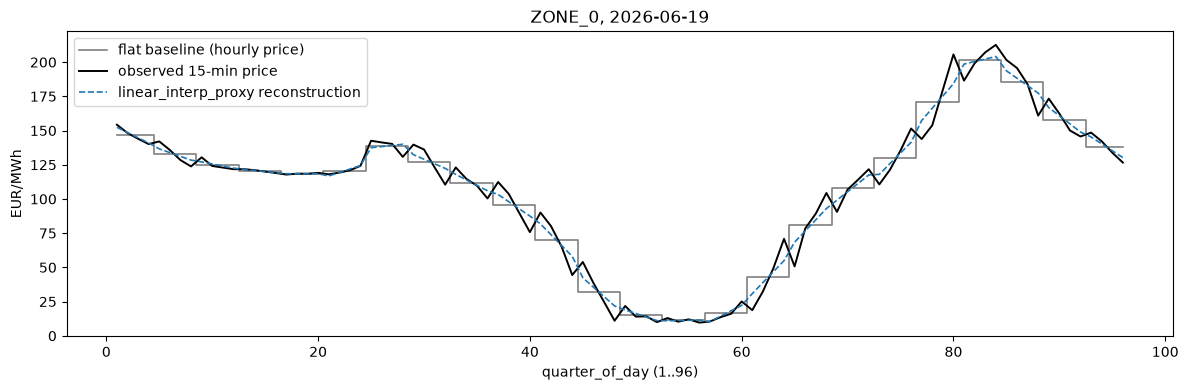

In [8]:
ex = df_t[(df_t[F.DATE] == '2026-06-19') & (df_t[F.ZONE] == 'ZONE_0')].merge(
    geo[[*F.HOUR_KEYS, 'slope_centered']], on=F.HOUR_KEYS
)
ex['linear'] = F.reconstruct_prices(ex, (ex[F.QUARTER] - 2.5) / 4 * ex['slope_centered'])
x = (ex[F.HOUR] - 1) * 4 + ex[F.QUARTER]

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(x, ex[F.HOURLY], where='mid', color='grey', lw=1.2, label='flat baseline (hourly price)')
ax.plot(x, ex[F.PRICE], color='black', lw=1.4, label='observed 15-min price')
ax.plot(x, ex['linear'], color='tab:blue', lw=1.2, ls='--', label='linear_interp_proxy reconstruction')
ax.set(xlabel='quarter_of_day (1..96)', ylabel='EUR/MWh', title='ZONE_0, 2026-06-19')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'dataprocess_example_day.png', dpi=120)
plt.show()

## Stage 3: historical quarter-hour features (strictly dates < D)

`F.history_panel` turns the quarter-hour history into one row per `(date, zone, hour, quarter)` with the observed price, the intra-hour spread, and **that history day's own** `slope_centered` (same geometry code as Stage 2). `F.historical_features` places these values on a calendar-day grid (one row per calendar day, one column per `(zone, hour, quarter)`) and reads them only through explicit day shifts k >= 1:

| Group | Definition (per zone, hour, quarter) |
|---|---|
| Exact lags | `spread_lag_{1,2,3,7,14}d` = spread on calendar day D-k |
| Rolling | `spread_roll{3,7,14}d_{mean,median,std}` over calendar days D-w..D-1 (NaN-aware; std needs >= 2 days) |
| Weekday-matched | `spread_dow4_mean` = mean of D-7, D-14, D-21, D-28 (same weekday, last 4 occurrences) |
| Slope response | `slope_beta_28d`, `slope_alpha_28d`: ridge-shrunk OLS of spread on that day's `slope_centered` over D-28..D-1 (>= 7 valid days, ridge 1 (EUR/MWh)^2 added to var(slope)); `slope_response_pred = alpha + beta * slope_centered(D)` |
| Boundary continuity | for `hour_index == 1` only: `prev_day_last_qh_price`, `prev_day_last_qh_spread` (D-1, h24, q4) and `prev_day_last_qh_gap = price(D-1, 24, 4) - H_D(1)` |
| Meta | `history_days_available` = number of history dates < D (identifies warm-up rows) |

Why this is leak-free by construction: the value for date D is assembled only from grid rows D-k with k >= 1. A training history that also contains D and later dates therefore gives **exactly** the same values as the jury's `history_15min.csv`, which stops at D-1. Missing days (DST gaps, jury gaps) stay NaN instead of being replaced by the previous available row. Nothing is fitted across dates, so there are no learned statistics that could absorb validation information.

The slope-response feature captures *how* each (zone, hour, quarter) has recently responded to the hourly ramp, which a plain recent average cannot do. The pooled train-split coefficients below show the effect is large and differs by quarter (positive for late quarters, negative for early quarters) and by zone.

In [9]:
panel = F.history_panel(df15)
train_panel = panel[F.assign_split(panel[F.DATE]) == 'train']

def pooled_beta(g):
    x, y = g['slope_centered'], g[F.TARGET]
    return ((x - x.mean()) * (y - y.mean())).mean() / x.var(ddof=0)

print('Pooled OLS slope of target_spread on slope_centered, train split (rows: zone, columns: quarter)')
train_panel.groupby([F.ZONE, F.QUARTER])[[F.TARGET, 'slope_centered']].apply(pooled_beta).unstack().round(3)

Pooled OLS slope of target_spread on slope_centered, train split (rows: zone, columns: quarter)


quarter_index,1,2,3,4
market_id,,,,
ZONE_0,-0.818,-0.269,0.257,0.831
ZONE_1,-0.877,-0.292,0.271,0.897
ZONE_2,-0.620,-0.224,0.208,0.636
ZONE_3,-0.714,-0.182,0.178,0.718


## Stage 4: `build_features`, dtypes, leakage checks, save

```python
build_features(df_hourly, df_history_15min, target_df=None)
```

- `df_hourly` has the `test_hourly.csv` schema; `df_history_15min` has the `history_15min.csv` schema.
- Training: `build_features(derive_hourly(train15), train15, target_df=train15)`. Inference: `build_features(test_hourly, history_15min)`; the code path is identical except for attaching the target.
- Dtypes: `market_id`, `hour_index`, `quarter_index`, `day_of_week` and `month` are `category` with **fixed** category lists, so the codes match between training and test. Flags are `int8`; `day_of_year`, `week_of_year` and `quarter_of_day` are `int16`. Engineered floats are `float32`; `hourly_price_eur_mwh`, `price_eur_mwh` and `target_spread` stay `float64`, so the 1e-4 reconstruction is not affected by float32 rounding.
- For XGBoost use `enable_categorical=True`; for LightGBM pandas categoricals are picked up automatically; for CatBoost pass `cat_features=meta['categorical_cols']`.

In [10]:
features = F.build_features(hourly, df15, target_df=df15)
assert len(features) == len(df15) and not features.duplicated(F.QH_KEYS).any()
print(f'{features.shape[0]:,} rows x {features.shape[1]} columns | {len(F.FEATURE_COLS)} features | '
      f'{features.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory')
features.dtypes.astype(str).value_counts().to_frame('n_columns')

139,392 rows x 80 columns | 74 features | 40.6 MB in memory


,n_columns
float32,54
int8,10
category,6
int16,3
float64,3
datetime64[us],2
Int64,1
int32,1


In [11]:
pd.DataFrame({group: [len(cols), ', '.join(cols)] for group, cols in F.FEATURE_GROUPS.items()},
             index=['n', 'columns']).T

,n,columns
categorical,5,"market_id, hour_index, quarter_index, day_of_w..."
calendar,17,"is_weekend, day_of_year, week_of_year, quarter..."
hourly_geometry,10,"hourly_price_eur_mwh, diff_prev_1h, diff_prev_..."
quarter_interactions,4,"q_centered, linear_interp_proxy, q_x_diff_prev..."
daily_context,10,"daily_mean, daily_std, daily_min, daily_max, d..."
cross_zone,6,"sys_mean_hourly, sys_std_hourly, sys_mean_slop..."
history_lags,5,"spread_lag_1d, spread_lag_2d, spread_lag_3d, s..."
history_rolling,10,"spread_roll3d_mean, spread_roll3d_median, spre..."
slope_response,3,"slope_beta_28d, slope_alpha_28d, slope_respons..."
boundary,3,"prev_day_last_qh_price, prev_day_last_qh_sprea..."


### Leakage and correctness checks

1. **Column check.** No target, observed price, raw time index or split label is in `feature_cols`.
2. **Time semantics.** `unix_timestamp` respects CET (UTC+1) in winter and CEST (UTC+2) in summer.
3. **Truncation invariance.** For each check date D, the features are rebuilt exactly as the jury would supply the data (the hourly curve of D only, plus history < D) and must match the full training build **bit for bit**. The dates include the first day, the days right after both DST gaps, and the last day.
4. **Perturbation.** D's quarter-hour prices in the history are changed by +50/-50/+50/-50 EUR/MWh (the hourly mean is unchanged): D's features must not move at all.
5. **Gap handling.** Jury-format input where D-1 is missing from the history: the build still works; the D-1 lag, the D-1 boundary and `diff_prev_1h` at h=1 become NaN, and the rolling windows use the remaining days.

In [12]:
forbidden = {F.PRICE, F.TARGET, F.DATE, 'timestamp', 'unix_timestamp', 'split'}
assert not forbidden & set(F.FEATURE_COLS)
assert set(F.FEATURE_COLS) <= set(features.columns)

expected_utc = {
    '2025-10-01': '2025-09-30 22:00',  # CEST
    '2026-01-15': '2026-01-14 23:00',  # CET
    '2026-06-19': '2026-06-18 22:00',  # CEST
}
for day, utc in expected_utc.items():
    row = features[(features[F.DATE] == day) & (features[F.HOUR] == 1) & (features[F.QUARTER] == 1)].iloc[0]
    got = pd.Timestamp(int(row['unix_timestamp']), unit='s')
    assert got == pd.Timestamp(utc), (day, got)
assert features['unix_timestamp'].notna().all()
print('column and time-semantics checks passed')

column and time-semantics checks passed


In [13]:
check_dates = ['2025-10-01', '2025-10-02', '2025-10-15', '2025-10-27', '2025-12-24',
               '2026-02-14', '2026-03-30', '2026-06-19', '2026-08-31', '2026-09-30']
truncation = F.truncation_invariance_check(df15, features, check_dates)
assert truncation['rows_match'].all()
assert (truncation['max_abs_diff'] == 0).all() and (truncation['nan_mismatch'] == 0).all()
truncation

,date,rows_match,max_abs_diff,nan_mismatch
0,2025-10-01,True,0.0,0
1,2025-10-02,True,0.0,0
2,2025-10-15,True,0.0,0
3,2025-10-27,True,0.0,0
4,2025-12-24,True,0.0,0
5,2026-02-14,True,0.0,0
6,2026-03-30,True,0.0,0
7,2026-06-19,True,0.0,0
8,2026-08-31,True,0.0,0
9,2026-09-30,True,0.0,0


In [14]:
perturbation = pd.DataFrame([F.perturbation_check(df15, features, d) for d in ['2025-11-20', '2026-03-30', '2026-09-30']])
assert (perturbation['max_abs_diff'] == 0).all() and (perturbation['nan_mismatch'] == 0).all()
perturbation

,date,delta,rows_match,max_abs_diff,nan_mismatch
0,2025-11-20,50.0,True,0.0,0
1,2026-03-30,50.0,True,0.0,0
2,2026-09-30,50.0,True,0.0,0


In [15]:
D = pd.Timestamp('2026-09-30')
test_hourly = F.derive_hourly(df15[df15[F.DATE] == D])  # test_hourly.csv schema
history_gap = df15[df15[F.DATE] < D - pd.Timedelta(days=1)]  # history without D-1
gap_feats = F.build_features(test_hourly, history_gap)

assert len(gap_feats) == 4 * 96 and F.TARGET not in gap_feats and F.PRICE not in gap_feats
h1 = gap_feats[F.HOUR] == 1
summary = {
    'spread_lag_1d all NaN': bool(gap_feats['spread_lag_1d'].isna().all()),
    'spread_lag_2d all present': bool(gap_feats['spread_lag_2d'].notna().all()),
    'diff_prev_1h NaN at h=1': bool(gap_feats.loc[h1, 'diff_prev_1h'].isna().all()),
    'slope_centered defined everywhere': bool(gap_feats['slope_centered'].notna().all()),
    'prev_day_last_qh_price NaN at h=1': bool(gap_feats.loc[h1, 'prev_day_last_qh_price'].isna().all()),
    'spread_roll3d_mean present (uses D-3, D-2)': bool(gap_feats['spread_roll3d_mean'].notna().all()),
}
assert all(summary.values())
summary

{'spread_lag_1d all NaN': True,
 'spread_lag_2d all present': True,
 'diff_prev_1h NaN at h=1': True,
 'slope_centered defined everywhere': True,
 'prev_day_last_qh_price NaN at h=1': True,
 'spread_roll3d_mean present (uses D-3, D-2)': True}

### Diagnostics

**Missing values.** Trees handle NaN natively, so boundary and warm-up NaNs are kept rather than imputed (imputation would differ between training and test). The `prev_day_last_qh_*` features are NaN by design outside `hour_index == 1`. Warm-up rows (the first ~28 days, where the 28-day windows are not yet full) can be filtered or down-weighted with `history_days_available`.

In [16]:
nan_rate = features[F.FEATURE_COLS].isna().mean()
warmup_days = features.loc[features['history_days_available'] < F.MAX_LOOKBACK_DAYS, F.DATE].nunique()
print(f'{(nan_rate > 0).sum()} of {len(F.FEATURE_COLS)} features contain NaN; '
      f'{warmup_days} warm-up days with < {F.MAX_LOOKBACK_DAYS} history days')
nan_rate[nan_rate > 0].sort_values(ascending=False).round(4).to_frame('nan_rate')

28 of 74 features contain NaN; 28 warm-up days with < 28 history days


,nan_rate
prev_day_last_qh_gap,0.9587
prev_day_last_qh_price,0.9587
prev_day_last_qh_spread,0.9587
diff_next_2h,0.0833
spread_lag_14d,0.0441
curvature_1h,0.0420
diff_next_1h,0.0417
q_x_diff_next_1h,0.0417
spread_lag_7d,0.0248
slope_beta_28d,0.0193


**Near-duplicate features.** Several engineered columns are near-linear transforms of each other (for example `diff_prev_2h` vs `diff_prev_1h`, the rolling mean vs median, or `quarter_sin/cos` vs `q_centered`). Trees tolerate this, but it splits importance between columns and adds noise to split selection. All features are kept here; prune after a first model using importance on the **training/validation split only**. The pairs below have |Pearson r| >= 0.95 on the train split.

In [17]:
numeric_cols = [c for c in F.FEATURE_COLS if c not in F.CATEGORICAL_COLS]
corr = features.loc[features['split'] == 'train', numeric_cols].astype('float64').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
near_duplicates = upper[upper >= 0.95].sort_values(ascending=False)
near_duplicates.round(3).to_frame('abs_corr')

abs_corr
is_daytime          is_nighttime              1.000
daily_std           daily_range               0.975
spread_roll14d_mean spread_roll14d_median     0.972
spread_roll7d_mean  spread_roll14d_mean       0.963
                    spread_roll7d_median      0.962
spread_roll3d_mean  spread_roll3d_median      0.959

**Signal sanity check (not a model).** Each single feature is used directly as the spread prediction (NaN set to 0), re-centred with `reconstruct_prices`, and scored with the official MAE. Nothing is fitted here, so this is only a check that the features carry shape information. Every reconstruction also passes the hourly constraint. Lower is better.

In [18]:
candidates = ['linear_interp_proxy', 'spread_lag_1d', 'spread_lag_7d', 'spread_roll7d_mean',
              'spread_roll14d_median', 'spread_dow4_mean', 'slope_response_pred']
base = features[[*F.QH_KEYS, F.HOURLY, F.PRICE, 'split']].copy()
signal = {'flat baseline': F.mae_table(base.assign(pred=base[F.HOURLY]), 'pred')['equal_zone_mean']}
for col in candidates:
    pred = F.reconstruct_prices(base, features[col].astype('float64').fillna(0.0))
    scored = base.assign(pred=pred)
    assert F.check_hourly_constraint(scored.rename(columns={'pred': F.PRED}), hourly)['compliant']
    signal[col] = F.mae_table(scored, 'pred')['equal_zone_mean']
signal = pd.DataFrame(signal).T
signal.round(3)

,train,validation,test
flat baseline,7.091,7.619,9.718
linear_interp_proxy,5.219,5.385,6.629
spread_lag_1d,6.253,6.433,7.979
spread_lag_7d,6.686,7.218,8.491
spread_roll7d_mean,5.249,5.525,6.648
spread_roll14d_median,5.040,5.352,6.256
spread_dow4_mean,5.845,6.032,6.673
slope_response_pred,4.248,4.329,5.334


Every candidate beats the flat baseline in all three splits. The rolling slope response is the strongest single signal: it roughly halves the flat-baseline MAE without any model. These scores use the full history; under the fold protocols of Stage 5, evaluated dates have much less history (see the coverage table there). The plain recent averages (lags, rolling mean/median) carry less information than the hourly ramp, which is why the GBDT should combine both families.

### Modelling notes for the GBDT stage

- **Target redundancy and loss.** The four spreads of an hour sum to zero, so a quarter-level model predicts one degree of freedom too many. That is fine because the final prediction is always re-centred with `reconstruct_prices`. Re-centring changes the predictions, however, so the quantity to optimise and validate is the **MAE after re-centring**, not the raw L1 loss on `target_spread`. Use an L1 / MAE objective (`reg:absoluteerror`, `MAE`, `objective='l1'`) and report the re-centred MAE per zone and the equal-zone average against the flat baseline.
- **Zone weighting.** The score weights zones equally and every zone has the same number of rows, so unweighted training already matches the metric.
- **Do not use** `timestamp`, `unix_timestamp`, `delivery_date` or `split` as features. `day_of_year`, `month` and `week_of_year` have seen each season only once (one training year), so check their importance and validation effect before keeping them.
- **Frozen inference.** After the freeze, `build_features(test_hourly, history_15min)` is run unchanged; recent history only feeds these fixed rules (lags, windows, slope response). Nothing is refitted.

### Save

The enriched table and its metadata are written to `data/enriched/` (the original CSV is untouched). Parquet keeps `market_id` as a category but returns the integer-coded categoricals (`hour_index`, `quarter_index`, `day_of_week`, `month`) as `int64`, so read the file with `F.load_enriched`, which restores the fixed category lists. The round-trip below checks that all dtypes and categories are identical.

In [19]:
meta = F.feature_metadata(features, extra={
    'source_file': 'data/train_prices_15min.csv',
    'build_call': 'build_features(derive_hourly(train15), train15, target_df=train15)',
    'inference_call': 'build_features(test_hourly, history_15min)',
    'excluded_dst_dates': schema_report['missing_calendar_dates'],
    'versions': VERSIONS,
    'flat_baseline_mae': {split: {k: round(float(v), 6) for k, v in row.items()} for split, row in flat_mae.iterrows()},
    'checks': {
        'truncation_invariance_dates': check_dates,
        'truncation_invariance_passed': True,
        'perturbation_dates': perturbation['date'].tolist(),
        'perturbation_passed': True,
        'hourly_constraint_demo_passed': True,
    },
    'near_duplicate_pairs_train_abs_corr_ge_0_95': [[a, b, round(float(v), 4)] for (a, b), v in near_duplicates.items()],
})
paths = F.save_enriched(features, meta, OUT_DIR)

reloaded = F.load_enriched(paths['parquet'])
assert reloaded.shape == features.shape
assert (reloaded.dtypes.astype(str) == features.dtypes.astype(str)).all()
for col in F.CATEGORICAL_COLS:
    assert list(reloaded[col].cat.categories) == list(features[col].cat.categories)
print(paths)
print(f"Parquet size: {Path(paths['parquet']).stat().st_size / 1e6:.1f} MB")

{'parquet': '/Users/dobri/git/AET-Neural-Wave/data/enriched/train_enriched.parquet', 'metadata': '/Users/dobri/git/AET-Neural-Wave/data/enriched/feature_metadata.json'}
Parquet size: 17.3 MB


## Stage 5: evaluation splits (MOSAIC, HORIZON, HARVEST)

The static labels above serve only as diagnostics. Models are selected and evaluated on the fold manifests of [`scripts/agent/create_validation_splits.py`](../scripts/agent/create_validation_splits.py) (details in [`docs/validation_protocols.md`](../docs/validation_protocols.md)):

| Code name | Strategy | Folds | Training dates | Evaluated dates | Role |
|---|---|---:|---|---|---|
| `MOSAIC` | `monthly_cv` | 11 | the other 10 months of 2025-11..2026-09 | one month (validation) | model selection |
| `HORIZON` | `chronological` | 8 | all months from 2025-11 up to the evaluated one (at least three) | the next month, 2026-02..2026-09 (validation) | temporal robustness |
| `HARVEST` | `october_holdout` | 1 | 2025-11..2026-09 (333 dates) | October 2025 (test) | final seasonal transfer; never used for any choice |

- **Dates.** Dates always stay whole, with all four zones. October 2025 is reserved in every MOSAIC and HORIZON fold. In HORIZON, the months after the evaluated one are marked `unused`.
- **Per-fold enrichment.** Each fold is enriched separately by `src.evaluation.enrichment.enrich_fold`. For every row, training or evaluated, the history behind its features consists only of that fold's **training dates** strictly before the row's date.
- **What never counts as history:** held-out, reserved and unused dates, including the earlier days of the evaluated month. This is the conservative policy of the protocol document.

The next cell runs `write_splits` (the same call as the CLI) only if the fold directory is missing. Otherwise it checks the existing directory: the same source file (SHA-256), and the same date assignments as a fresh `build_folds` on the validated data. The directory is never overwritten.

In [20]:
import hashlib
import json

from src.evaluation import splits as S

PROTOCOL_DIR = ROOT / 'artifacts' / 'splits' / 'monthly_protocol_enriched'
if not PROTOCOL_DIR.exists():
    S.write_splits(DATA_PATH, PROTOCOL_DIR, enrich_features=True)
manifest = json.loads((PROTOCOL_DIR / 'manifest.json').read_text())
assert manifest['data_sha256'] == hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert manifest['monthly_scope'] == 'reserve-october' and manifest['feature_enrichment']['enabled']
assert manifest['missing_dates_preserved'] == schema_report['missing_calendar_dates']

CODE_NAMES = {'monthly_cv': 'MOSAIC', 'chronological': 'HORIZON', 'october_holdout': 'HARVEST'}
PARTS = ('train', 'validation', 'test', 'reserved', 'unused')
all_dates = tuple(df15[F.DATE].dt.strftime('%Y-%m-%d').unique())
expected = {(f.strategy, f.fold_id): f for f in S.build_folds(all_dates, 'reserve-october',
                                                             manifest['chronological_min_train_months'])}
fold_splits, rows = {}, []
for entry in manifest['folds']:
    split = json.loads((PROTOCOL_DIR / entry['path']).read_text())
    ref = expected[(split['strategy'], split['fold_id'])]
    assert all(tuple(split[p]) == getattr(ref, p) for p in PARTS), split['fold_id']
    fold_splits[split['fold_id']] = split
    evaluated = split['validation'] or split['test']
    rows.append({'protocol': CODE_NAMES[split['strategy']], 'fold_id': split['fold_id'],
                 'evaluated': evaluated[0][:7], 'evaluated as': 'validation' if split['validation'] else 'test',
                 **{f'{p} dates': len(split[p]) for p in PARTS}})
assert len(expected) == len(fold_splits) == 20
fold_table = pd.DataFrame(rows)
print(f"{len(fold_table)} folds in {PROTOCOL_DIR.relative_to(ROOT)}; source SHA-256 {manifest['data_sha256'][:12]}...")
fold_table

20 folds in artifacts/splits/monthly_protocol_enriched; source SHA-256 f71ae6dbcca5...


,protocol,fold_id,evaluated,evaluated as,train dates,validation dates,test dates,reserved dates,unused dates
0,MOSAIC,holdout-2025-11,2025-11,validation,303,30,0,30,0
1,MOSAIC,holdout-2025-12,2025-12,validation,302,31,0,30,0
2,MOSAIC,holdout-2026-01,2026-01,validation,302,31,0,30,0
3,MOSAIC,holdout-2026-02,2026-02,validation,305,28,0,30,0
4,MOSAIC,holdout-2026-03,2026-03,validation,303,30,0,30,0
5,MOSAIC,holdout-2026-04,2026-04,validation,303,30,0,30,0
6,MOSAIC,holdout-2026-05,2026-05,validation,302,31,0,30,0
7,MOSAIC,holdout-2026-06,2026-06,validation,303,30,0,30,0
8,MOSAIC,holdout-2026-07,2026-07,validation,302,31,0,30,0
9,MOSAIC,holdout-2026-08,2026-08,validation,302,31,0,30,0


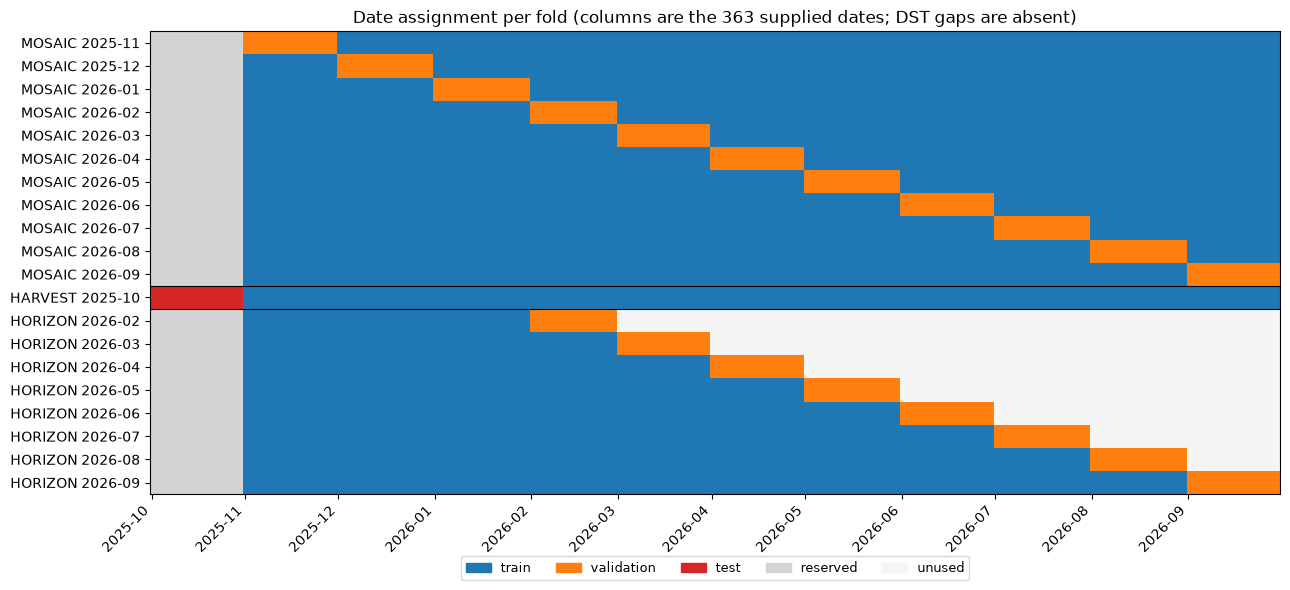

In [21]:
PART_CODES = {'train': 0, 'validation': 1, 'test': 2, 'reserved': 3, 'unused': 4}
date_index = pd.to_datetime(pd.Series(all_dates))
grid = np.full((len(fold_table), len(all_dates)), np.nan)
for i, fold_id in enumerate(fold_table['fold_id']):
    for part, code in PART_CODES.items():
        grid[i, date_index.isin(pd.to_datetime(fold_splits[fold_id][part])).to_numpy()] = code

cmap = matplotlib.colors.ListedColormap(['tab:blue', 'tab:orange', 'tab:red', 'lightgrey', 'whitesmoke'])
fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(grid, aspect='auto', cmap=cmap, vmin=-0.5, vmax=4.5, interpolation='nearest')
month_starts = [i for i, d in enumerate(all_dates) if d.endswith('-01')]
ax.set_xticks(month_starts, [all_dates[i][:7] for i in month_starts], rotation=45, ha='right')
ax.set_yticks(range(len(fold_table)), fold_table['protocol'] + ' ' + fold_table['evaluated'])
for y in np.flatnonzero(fold_table['protocol'].ne(fold_table['protocol'].shift()).to_numpy())[1:] - 0.5:
    ax.axhline(y, color='black', lw=0.8)
ax.legend(handles=[matplotlib.patches.Patch(color=cmap(c), label=p) for p, c in PART_CODES.items()],
          ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)
ax.set_title('Date assignment per fold (columns are the 363 supplied dates; DST gaps are absent)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'validation_protocols.png', dpi=110, bbox_inches='tight')
plt.show()

### Fold-file checks and history coverage

For every fold and partition, the enriched files must contain exactly the assigned dates, with 4 zones x 96 quarters each. They must have the feature columns of `src.gradient.features`, the matching `split` labels, a target that averages to zero within every hour, and no row from a reserved or unused date. The same pass measures how often the history-based features are missing in training rows and in evaluated rows.

In [22]:
HISTORY_COLS = F.FEATURE_GROUPS['history_lags'] + F.FEATURE_GROUPS['history_rolling'] + F.FEATURE_GROUPS['slope_response']
COVERAGE_COLS = ['spread_lag_1d', 'spread_roll7d_mean', 'spread_roll14d_median', 'spread_dow4_mean', 'slope_response_pred']
coverage = []
for entry in manifest['folds']:
    leaf = (PROTOCOL_DIR / entry['path']).parent
    split, meta_f = fold_splits[leaf.name], json.loads((leaf / 'feature_metadata.json').read_text())
    assert meta_f['feature_cols'] == F.FEATURE_COLS and meta_f['history_dates'] == split['train']
    excluded = pd.to_datetime(split['reserved'] + split['unused'])
    for part in ('train', 'validation', 'test'):
        cols = [*F.QH_KEYS, 'split', F.TARGET, *HISTORY_COLS]
        f = pd.read_parquet(leaf / meta_f['files'][part], columns=cols)
        assert len(f) == 384 * len(split[part])
        assert sorted(f[F.DATE].dt.strftime('%Y-%m-%d').unique()) == split[part]
        assert f.groupby([F.DATE, F.ZONE]).size().eq(96).all() if len(f) else True
        assert (f['split'].astype(str) == part).all() and not f[F.DATE].isin(excluded).any()
        assert f.groupby([F.DATE, F.ZONE, F.HOUR])[F.TARGET].mean().abs().max() < 1e-9 if len(f) else True
        if len(f):
            coverage.append({'protocol': CODE_NAMES[split['strategy']], 'rows': 'train' if part == 'train' else 'evaluated',
                             'n': len(f), 'history_nan_any': f[HISTORY_COLS].isna().any(axis=1).mean(),
                             **{c: f[c].isna().mean() for c in COVERAGE_COLS}})
print('fold files: dates, rows, columns, labels, target centring and exclusions all checked')
cov = pd.DataFrame(coverage)
weighted = cov.groupby(['protocol', 'rows'], sort=False).apply(
    lambda g: pd.Series({c: np.average(g[c], weights=g['n']) for c in ['history_nan_any', *COVERAGE_COLS]}),
    include_groups=False)
print('Share of rows with a missing value, pooled over the folds of each protocol')
weighted.round(3)

fold files: dates, rows, columns, labels, target centring and exclusions all checked
Share of rows with a missing value, pooled over the folds of each protocol


history_nan_any  spread_lag_1d  spread_roll7d_mean  spread_roll14d_median  spread_dow4_mean  slope_response_pred
protocol rows                                                                                                                       
MOSAIC   train                0.098          0.009               0.006                  0.006             0.042                0.042
         evaluated            0.973          0.970               0.790                  0.580             0.162                0.342
HARVEST  train                0.057          0.006               0.003                  0.003             0.021                0.021
         evaluated            1.000          1.000               1.000                  1.000             1.000                1.000
HORIZON  train                0.089          0.009               0.005                  0.005             0.036                0.036
         evaluated            0.971          0.967               0.768                  0.535             0.075                0.274

### History is rebuilt from training dates only (bit-exact)

For a few dates, the features are rebuilt the way the fold defines them: the hourly curve of D, and as history only the fold's training dates before D. The result must match the fold file **bit for bit**. The same dates in the full-history table of Stage 4 differ, because that table may use the held-out days as history. The checked dates cover:

- an evaluated date at the start and one late in a held-out month;
- a training date just after the held-out gap;
- a HORIZON validation date;
- a HARVEST (October) date, which has no earlier training date at all.

In [23]:
def rebuild_fold_rows(split, day):
    d = pd.Timestamp(day)
    history = df15[df15[F.DATE].isin(pd.to_datetime(split['train'])) & (df15[F.DATE] < d)]
    return F.build_features(F.derive_hourly(df15[df15[F.DATE] == d]), history)

history_checks = [('holdout-2026-03', '2026-03-01', 'validation'), ('holdout-2026-03', '2026-03-24', 'validation'),
                  ('holdout-2026-03', '2026-04-02', 'train'), ('through-2026-01-validate-2026-02', '2026-02-15', 'validation'),
                  ('october-2025', '2025-10-15', 'test')]
records = []
for fold_id, day, part in history_checks:
    split = fold_splits[fold_id]
    leaf = PROTOCOL_DIR / f"{split['strategy']}/{fold_id}"
    stored = F.load_enriched(leaf / f'{part}_enriched.parquet')
    stored = stored[stored[F.DATE] == day]
    fold_diff = F._compare_frames(stored, rebuild_fold_rows(split, day), F.FEATURE_COLS)
    static_diff = F._compare_frames(stored, features[features[F.DATE] == day], F.FEATURE_COLS)
    assert fold_diff['rows_match'] and fold_diff['max_abs_diff'] == 0 and fold_diff['nan_mismatch'] == 0
    records.append({'fold': fold_id, 'date': day, 'partition': part, 'vs fold rebuild: max diff': fold_diff['max_abs_diff'],
                    'vs fold rebuild: NaN mismatches': fold_diff['nan_mismatch'],
                    'vs full-history table: NaN mismatches': static_diff['nan_mismatch'],
                    'history NaN share': float(stored[HISTORY_COLS].isna().mean().mean())})
pd.DataFrame(records)

,fold,date,partition,vs fold rebuild: max diff,vs fold rebuild: NaN mismatches,vs full-history table: NaN mismatches,history NaN share
0,holdout-2026-03,2026-03-01,validation,0.0,0,0,0.000000
1,holdout-2026-03,2026-03-24,validation,0.0,0,6656,0.944444
2,holdout-2026-03,2026-04-02,train,0.0,0,4224,0.611111
3,through-2026-01-validate-2026-02,2026-02-15,validation,0.0,0,5504,0.777778
4,october-2025,2025-10-15,test,0.0,0,7040,1.000000


**What this means for the models.**

- **Training rows** see almost complete history. Only the first days after a gap lose it: after reserved October, after the held-out month, after the DST gaps.
- **Evaluated rows** lose most of it:
  - The 1-day lag is missing for almost every MOSAIC and HORIZON validation row; only the first day of a month can read the last training day.
  - The 7- and 14-day windows thin out within the month.
  - The 28-day slope response disappears after about day 22, when fewer than 7 training days remain in its window.
  - In HARVEST (October 2025, the first month of the data) every history feature is missing.
- **Why this matters:** a model that leans on the history features is tested on rows that differ from the rows it was trained on.

The GBDT notebooks therefore compare three feature sets: `raw` (4 columns), `curve` (the features computed from the hourly curve of D, which need no quarter-hour history) and `enriched` (all 74 features).

## Using the enriched dataset

```python
import json
import pandas as pd
from src.gradient import features as F

meta = json.load(open('data/enriched/feature_metadata.json'))
df = F.load_enriched('data/enriched/train_enriched.parquet')  # restores fixed categories
train = df[df['split'] == 'train']
X, y = train[meta['feature_cols']], train[meta['target_col']]
# xgboost.XGBRegressor(objective='reg:absoluteerror', enable_categorical=True, tree_method='hist').fit(X, y)
# catboost.CatBoostRegressor(loss_function='MAE', cat_features=meta['categorical_cols']).fit(X, y)

# fold-aware files for the evaluation protocols (Stage 5), e.g. one MOSAIC fold
fold = 'artifacts/splits/monthly_protocol_enriched/monthly_cv/holdout-2026-03'
train = F.load_enriched(f'{fold}/train_enriched.parquet')
valid = F.load_enriched(f'{fold}/validation_enriched.parquet')

# frozen inference for one evaluated date
test = F.build_features(F.load_hourly('test_hourly.csv'), F.load_15min('history_15min.csv'))
test[F.PRED] = F.reconstruct_prices(test, model.predict(test[meta['feature_cols']]))
assert F.check_hourly_constraint(test, F.load_hourly('test_hourly.csv'))['compliant']
```

## Summary

- Stage 1: validated schema (363 days x 4 zones x 96 quarters, DST dates excluded), derived the hourly reference, built `target_spread`, and showed that re-centring always satisfies the 1e-4 constraint. Flat baseline MAE per split is computed above.
- Stage 2: hourly-curve geometry of day D (slopes, curvature, quarter-slope interactions, daily and cross-zone context, calendar). D-1 boundary values come from the history, D+1 is never used, and the boundary rule is the same in training and test.
- Stage 3: calendar-day lags, rolling and weekday-matched spread statistics, and a rolling ridge regression of the spread on the hourly slope, all from dates strictly before D.
- Stage 4: one `build_features` entry point for training and inference, compact dtypes with fixed categories, and leakage checks (bit-exact truncation invariance, perturbation, gap handling), diagnostics and saved outputs with metadata.
- Stage 5: the MOSAIC (11), HORIZON (8) and HARVEST (1) folds from `create_validation_splits.py`, verified against a fresh `build_folds`. The fold files were checked for dates, rows, columns, labels and exclusions. History was rebuilt bit-exactly from training dates only. A coverage table shows how much history the evaluated rows lose under this conservative policy.